Hidden Workforce Group Discovery Using Census Data

In [346]:
# Step 1 – Import libraries and load dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans,AgglomerativeClustering
from sklearn.metrics import silhouette_score,adjusted_rand_score
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import dendrogram,linkage

import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("/content/adult_dataset.csv")
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [347]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB


In [348]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,46400.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,46400.000000
mean,38.679116,1.896641e+05,10.078089,1079.067626,87.502314,40.448599
std,13.952954,1.056040e+05,2.570973,7452.019058,403.004552,12.646992
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,255.000000,1.490400e+06,16.000000,99999.000000,4356.000000,250.000000


In [349]:
df.duplicated().sum()

np.int64(16)

In [350]:
# Clear the Duplicates

df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

In [351]:
# Checking the missing value nad Handling

df.isnull().sum()

,0
age,2442
workclass,3362
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,3357
relationship,0
race,0
sex,0


Step 2 – Data preprocessing

In [352]:
# Remove income column

df = df.drop("income",axis=1)

In [353]:
#df['occupation'].value_counts()
#df['workclass'].value_counts()
#df['native-country'].value_counts()     Replace ? with missing values


In [354]:
df = df.replace("?",np.nan)
df.isnull().sum()

,0
age,2442
workclass,5125
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,5115
relationship,0
race,0
sex,0


In [355]:
num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(include="object").columns

num_cols

Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='object')

In [356]:
cat_cols

Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='object')

In [357]:
# Handle missing values  -   Numerical columns → Median  -      Categorical columns → Mode

for i in num_cols:
  df[i] = df[i].fillna(df[i].median())

for i in cat_cols:
  df[i] = df[i].fillna(df[i].mode()[0])

df.isnull().sum()


,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


Detect and treat outliers using IQR

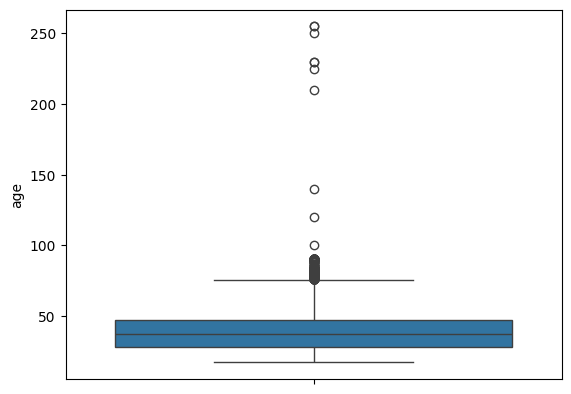

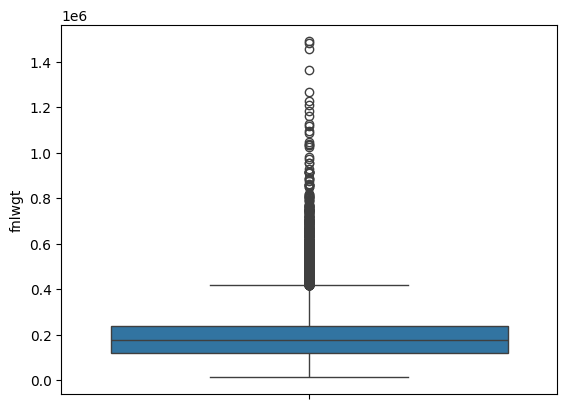

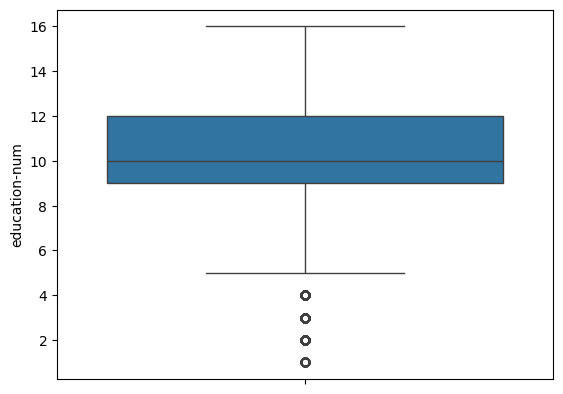

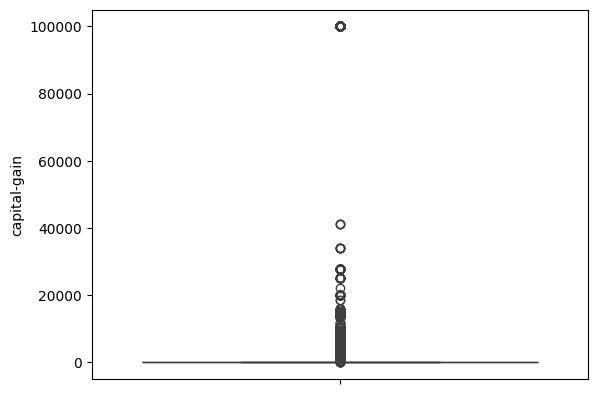

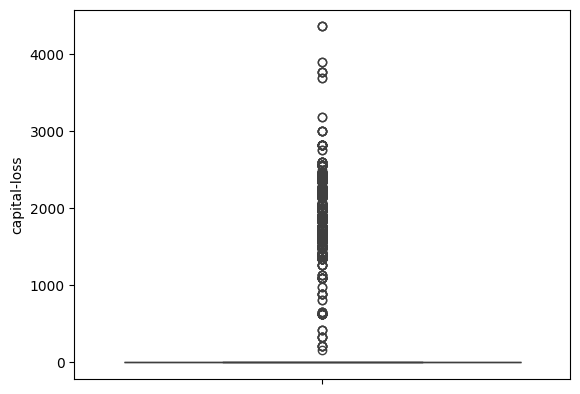

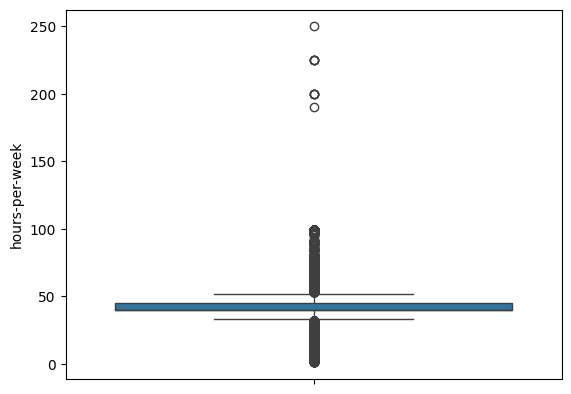

In [358]:
for i in num_cols:
  sns.boxplot(df[i])
  plt.show()


In [359]:
df[num_cols].skew()

,0
age,1.017826
fnlwgt,1.439357
education-num,-0.315970
capital-gain,11.892692
capital-loss,4.568956
hours-per-week,0.812937


In [360]:
# capital-gain and capital-loss contain many zeros. Their first and third quartiles are both zero, so ordinary IQR clipping would incorrectly remove legitimate nonzero observations.

# We will apply IQR clipping to age, fnlwgt and hours-per-week, and use log transformation for capital-gain and capital-loss.

outlier_cols = ["age","fnlwgt","hours-per-week"]
for i in outlier_cols:
  Q1 = df[i].quantile(0.25)
  Q3 = df[i].quantile(0.75)
  IQR = Q3 - Q1
  lower = Q1 - 1.5*IQR
  upper = Q3 + 1.5*IQR

df[i] = df[i].clip(lower,upper)


In [361]:
# Handling the skewness

df['capital-gain'] = np.log1p(df['capital-gain'])
df['capital-loss'] = np.log1p(df['capital-loss'])

df['fnlwgt'] = np.cbrt(df['fnlwgt'])
df['age'] = np.cbrt(df['age'])


In [362]:
df[num_cols].skew()

,0
age,0.147652
fnlwgt,-0.159213
education-num,-0.315970
capital-gain,3.112972
capital-loss,4.302144
hours-per-week,0.480415


In [363]:
df.head(3)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,3.391211,State-gov,42.638029,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,7.684784,0.0,40.0,United-States
1,3.684031,Self-emp-not-inc,43.675121,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.000000,0.0,32.5,United-States
2,3.361975,Private,59.967204,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.000000,0.0,40.0,United-States


Encode categorical variables

In [364]:
df_enc = pd.get_dummies(df,columns=cat_cols,drop_first=True,dtype="int")
df_enc.head(3)

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,3.391211,42.638029,13,7.684784,0.0,40.0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,3.684031,43.675121,13,0.000000,0.0,32.5,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,3.361975,59.967204,9,0.000000,0.0,40.0,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0


Scale numerical features

In [365]:
scaler = StandardScaler()
df_enc[num_cols] = scaler.fit_transform(df_enc[num_cols])
df_enc


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,0.146263,-1.181196,1.136533,2.844037,-0.221302,-0.187370,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,0.895515,-1.085463,1.136533,-0.297971,-0.221302,-1.430414,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,0.071456,0.418443,-0.419444,-0.297971,-0.221302,-0.187370,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
3,1.080396,0.577069,-1.197432,-0.297971,-0.221302,-0.187370,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
4,-0.761126,1.315601,1.136533,-0.297971,-0.221302,-0.187370,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,0.146263,0.416500,1.136533,-0.297971,-0.221302,-0.850327,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
48838,1.703999,1.205991,-0.419444,-0.297971,-0.221302,-0.187370,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
48839,0.071456,1.539460,1.136533,-0.297971,-0.221302,1.470021,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0
48840,0.502279,-1.076129,1.136533,3.220061,-0.221302,-0.187370,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0


EDA

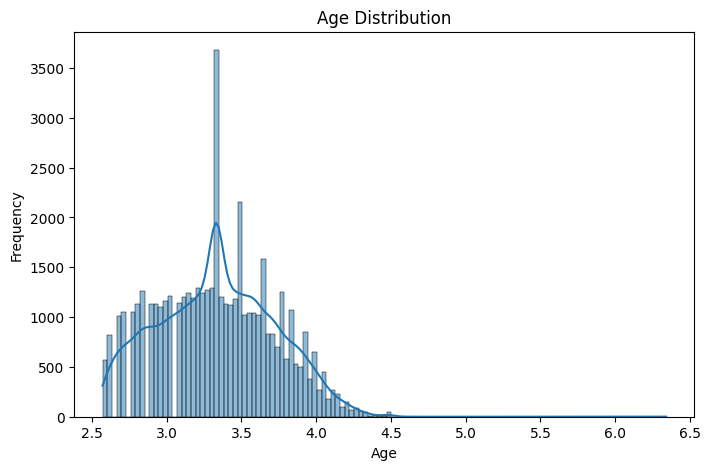

In [366]:
# Age distribution
plt.figure(figsize=(8,5))
sns.histplot(df["age"],kde=True)
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Age Distribution")
plt.show()

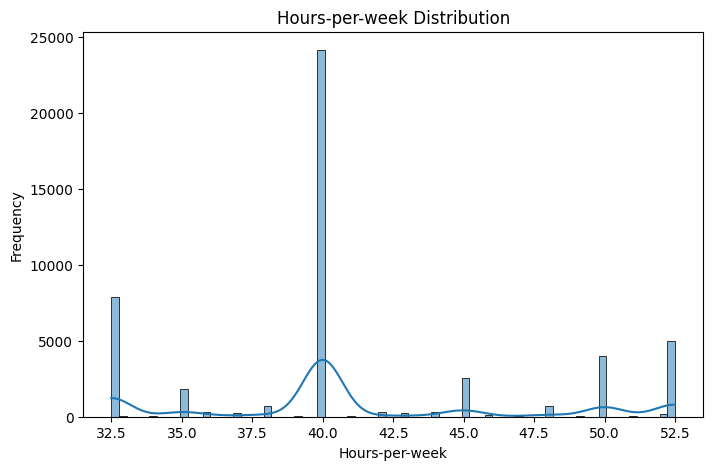

In [367]:
# Hours-per-week distribution

plt.figure(figsize=(8,5))
sns.histplot(df["hours-per-week"],kde=True)
plt.xlabel("Hours-per-week")
plt.ylabel("Frequency")
plt.title("Hours-per-week Distribution")
plt.show()


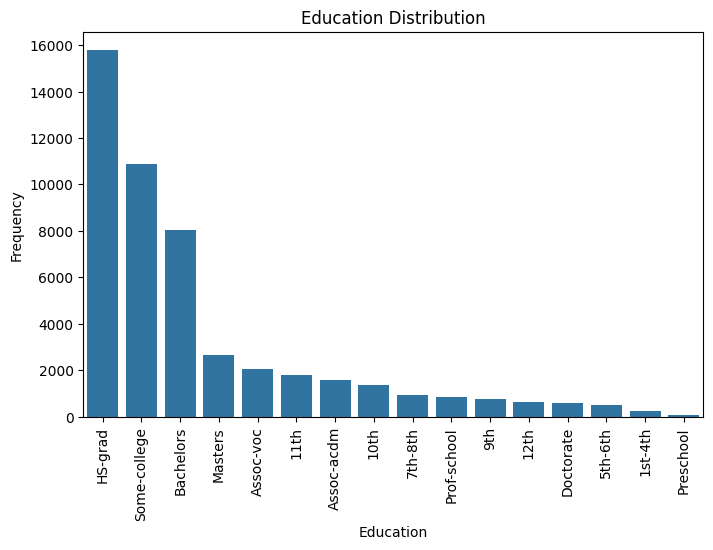

In [368]:
# Education distribution

plt.figure(figsize=(8,5))
sns.countplot(data=df,x="education",order=df["education"].value_counts().index)
plt.xlabel("Education")
plt.ylabel("Frequency")
plt.title("Education Distribution")
plt.xticks(rotation=90)
plt.show()

In [369]:
df[["capital-gain","capital-loss"]].skew()


,0
capital-gain,3.112972
capital-loss,4.302144


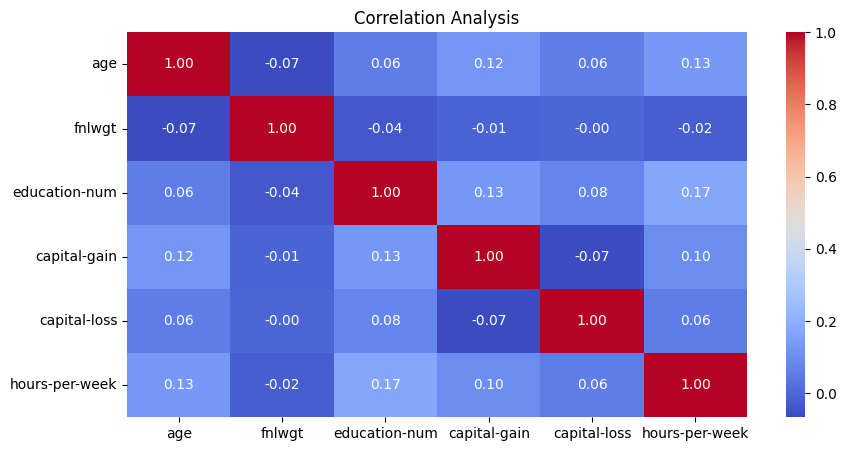

In [370]:
# Correlation analysis - Heatmap

plt.figure(figsize=(10,5))
sns.heatmap(df[num_cols].corr(),annot=True,fmt=".2f",cmap="coolwarm")
plt.title("Correlation Analysis")
plt.show()

K-Means clustering

In [371]:
# Elbow method

inertia = []

k_range = range(2,10)
for i in k_range:
  km = KMeans(n_clusters=i,random_state=42,n_init=10)
  km.fit(df_enc)
  inertia.append(km.inertia_)

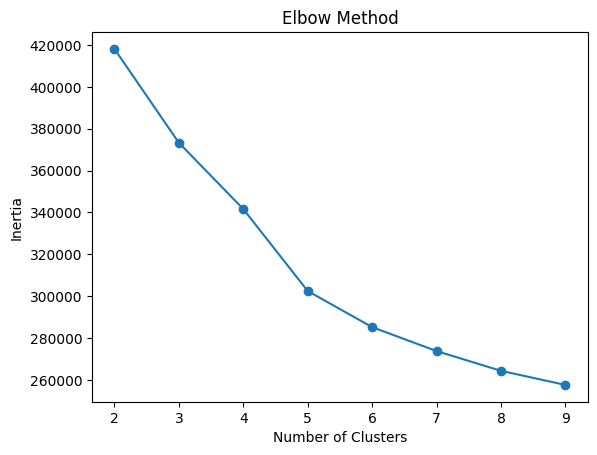

In [372]:
plt.plot(k_range,inertia,marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [373]:
# Silhouette score

sil_score = []

for i in range(2,10):
  km = KMeans(n_clusters=i,random_state=42,n_init=10)
  labels = km.fit_predict(df_enc)

  score = silhouette_score(df_enc,labels,sample_size=3000,random_state=42)
  sil_score.append(score)
  print("k:",i,"Silhouette score:",score)



k: 2 Silhouette score: 0.262289885386076
k: 3 Silhouette score: 0.11702287488936974
k: 4 Silhouette score: 0.12215972629664773
k: 5 Silhouette score: 0.14298098499220607
k: 6 Silhouette score: 0.1424429858878494
k: 7 Silhouette score: 0.13402350598095347
k: 8 Silhouette score: 0.12904075229566006
k: 9 Silhouette score: 0.11228764665865432


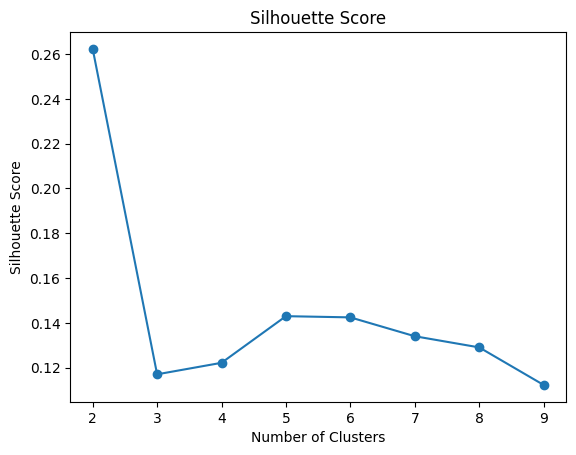

In [374]:
plt.plot(range(2,10),sil_score,marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score")
plt.show()

In [375]:
# Select optimal K and fit final K-Means

best_k = range(2,10)[np.argmax(sil_score)]
print("Best K:",best_k)


Best K: 2


In [376]:
# Final kmean model [km_cluster]

km = KMeans(n_clusters=best_k,random_state=42,n_init=10)
df["km_cluster"] = km.fit_predict(df_enc)
df["km_cluster"].value_counts()

,count
km_cluster,
1,44799
0,4027


 Agglomerative Clustering

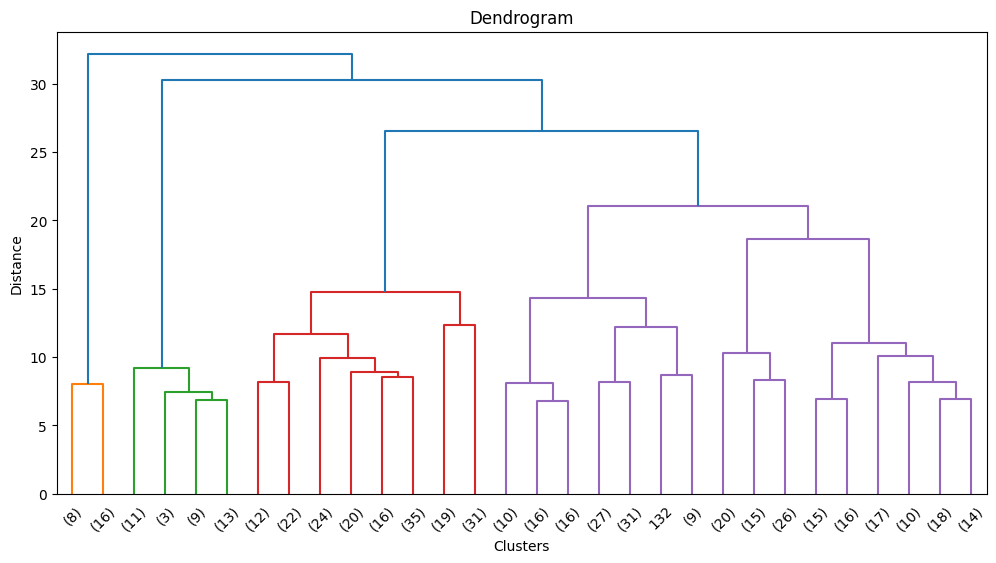

In [377]:
# Generate dendrogram

dendro = df_enc.sample(n=500,random_state=42)
Z = linkage(dendro,method="ward")

plt.figure(figsize=(12,6))
dendrogram(Z,truncate_mode="lastp",p=30)
plt.xlabel("Clusters")
plt.ylabel("Distance")
plt.title("Dendrogram")
plt.show()

In [378]:
# Apply Agglomerative Clustering

X_samples = df_enc.sample(n=2500,random_state=42)

agg = AgglomerativeClustering(n_clusters=best_k,linkage="ward")
agg_labels = agg.fit_predict(X_samples)

print("Agglomerative Cluster count :")
print(pd.Series(agg_labels).value_counts())

Agglomerative Cluster count :
0    2309
1     191
Name: count, dtype: int64


Compare K-Means and Agglomerative

In [379]:
# # Get corresponding K-Means labels

km_sample = df.loc[X_samples.index,'km_cluster'].values


comparision = pd.crosstab(km_sample,agg_labels,rownames=["K-Means"],colnames=["Agglomerative"])
comparision



Agglomerative,0,1
K-Means,,
0,0,191
1,2309,0


In [380]:
ari = adjusted_rand_score(km_sample,agg_labels)
print("Adjusted Rand Index:",ari)

Adjusted Rand Index: 1.0


Dimensionality Reduction using PCA

In [381]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(df_enc)
X_pca.shape

(48826, 2)

In [382]:
print("Total Explained Varience:", pca.explained_variance_ratio_.sum())

Total Explained Varience: 0.2750736944276297


Explained variance visualization

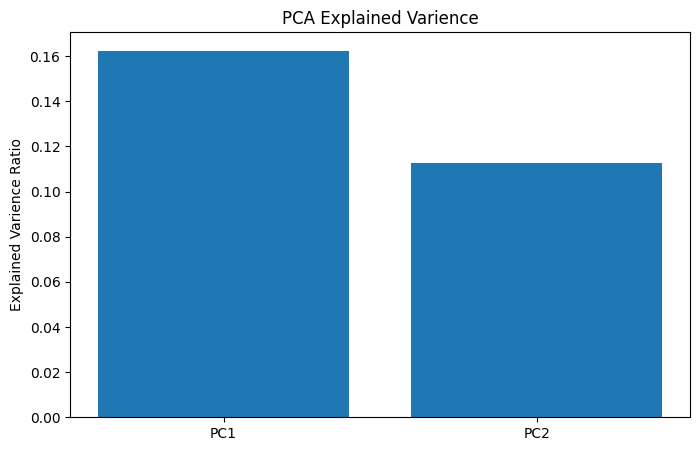

In [383]:
vari = pca.explained_variance_ratio_

plt.figure(figsize=(8,5))
plt.bar(["PC1","PC2"],vari)
plt.ylabel("Explained Varience Ratio")
plt.title("PCA Explained Varience")
plt.show()

In [384]:
# PC1 + PC2 = Total Variance  , PC1 has high Variance

PCA visualization – K-Means

In [385]:
print("X_pca shape:", X_pca.shape)
print("plot_idx:", plot_idx)
print("DataFrame shape:", df.shape)

print("Maximum plot_idx:", np.max(plot_idx))

X_pca shape: (48826, 2)
plot_idx: [35519 28449 36153 ... 19430 30047 19650]
DataFrame shape: (48826, 15)
Maximum plot_idx: 48816


In [386]:
df = df.reset_index(drop=True)
plot_idx = np.random.choice(len(df), 8000, replace=False)

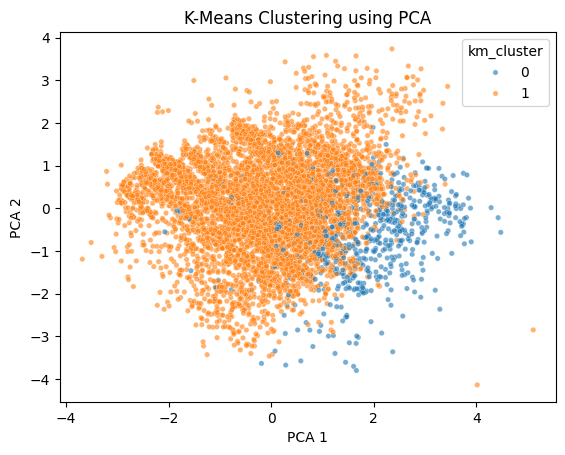

In [387]:
sns.scatterplot(
    x=X_pca[plot_idx, 0],
    y=X_pca[plot_idx, 1],
    hue=df.loc[plot_idx, "km_cluster"],
    palette="tab10",
    s=15,
    alpha=0.6
)

plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("K-Means Clustering using PCA")
plt.show()

PCA visualization – Agglomerative Clustering

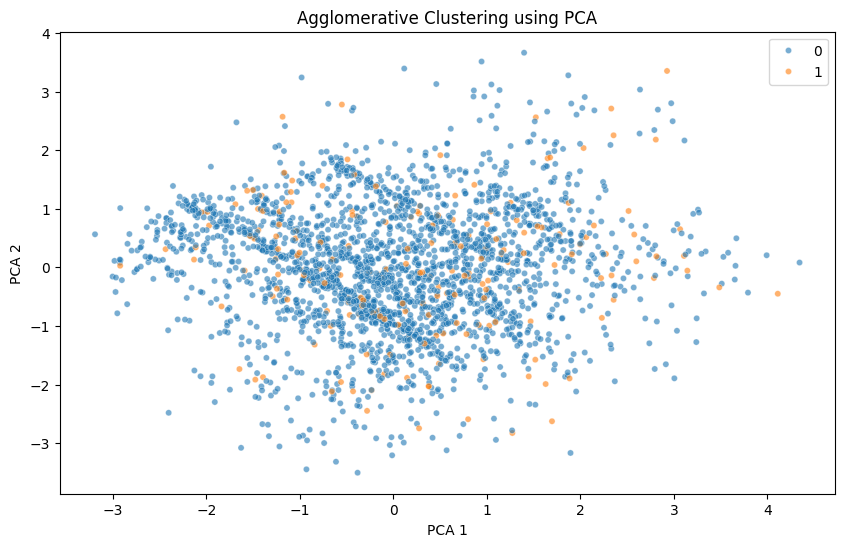

In [388]:
X_pca_sample = X_pca[X_samples.index]

plt.figure(figsize=(10,6))
sns.scatterplot(
    x=X_pca_sample[:, 0],
    y=X_pca_sample[:, 1],
    hue=agg_labels,
    palette="tab10",
    s=20,
    alpha=0.6
)
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Agglomerative Clustering using PCA")
plt.show()



Interpretation of PCA

In [389]:
# Variance captured by first two components

print(pca.explained_variance_ratio_.sum() * 100, "%")

27.50736944276297 %


In [390]:
# Cluster Seperablity in PCA space

# PCA visualization – K-Means has more visual seperablity since it represented in 2D


Cluster interpretation and workforce analysis

In [392]:
# Numerical cluster profiles

df_profile = df.copy()
df_profile["cluster"] = df["km_cluster"]
cluster_numeric = df_profile.groupby("cluster")[num_cols].mean()
cluster_numeric


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
cluster,,,,,,
0,3.490473,55.219099,11.072511,8.826412,0.000000,42.932083
1,3.319988,55.453468,9.988906,0.000884,0.382647,40.968571


In [393]:
# Catagorical cluster Profiles

cat_profile = df_profile.groupby('cluster')[cat_cols].agg(lambda x: x.mode().iloc[0])

print(cat_profile)

        workclass education      marital-status      occupation relationship  \
cluster                                                                        
0         Private   HS-grad  Married-civ-spouse  Prof-specialty      Husband   
1         Private   HS-grad  Married-civ-spouse  Prof-specialty      Husband   

          race   sex native-country  
cluster                              
0        White  Male  United-States  
1        White  Male  United-States  


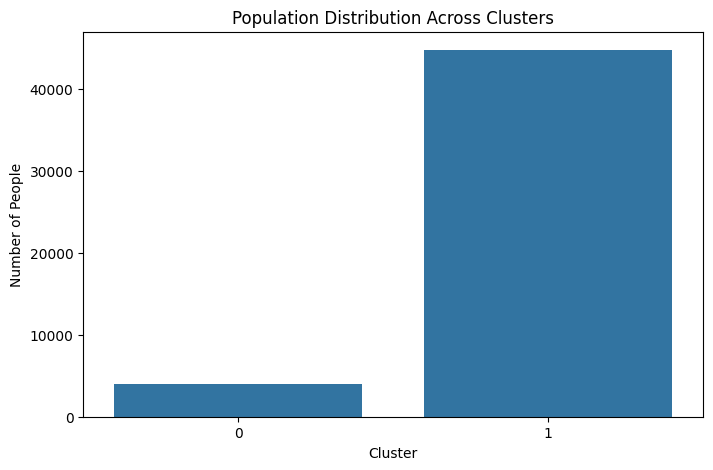

In [394]:
#Cluster population distribution

cluster_counts = df_profile['cluster'].value_counts().sort_index()

plt.figure(figsize=(8,5))

sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values
)

plt.xlabel("Cluster")
plt.ylabel("Number of People")

plt.title("Population Distribution Across Clusters")

plt.show()

Strategic recommendations for workforce planning

Possible population segment	      = Suggested workforce policy
Young adults with lower education = 	Vocational and technical training
People working long hours	        =   Work-life balance and employment protection
Experienced workers with higher education = 	Advanced skill development and leadership programs
People in lower-skilled occupations	= Digital literacy and reskilling
People outside regular employment categories	= Employment access and financial inclusion support